Reading Our files into a dataframe

In [2]:

import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

for file in Path("C:\\Users\\yalam\\Desktop\\dataanalysis\\projects").glob("*.csv"):
    df = pd.read_csv(file)

    print(f"\nFILE: {file.name}")
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print(df.head(3))



FILE: sample_-_superstore-Orders.csv
Shape: (10194, 21)
Columns: ['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']
   Row ID        Order ID Order Date Ship Date       Ship Mode Customer ID  \
0       1  US-2023-103800   1/3/2023  1/7/2023  Standard Class    DP-13000   
1       2  US-2023-112326   1/4/2023  1/8/2023  Standard Class    PO-19195   
2       3  US-2023-112326   1/4/2023  1/8/2023  Standard Class    PO-19195   

   Customer Name      Segment Country/Region        City  ... Postal Code  \
0  Darren Powers     Consumer  United States     Houston  ...       77095   
1  Phillina Ober  Home Office  United States  Naperville  ...       60540   
2  Phillina Ober  Home Office  United States  Naperville  ...       60540   

    Region       Product ID         

getting a gist of what sort of things we're dealing with 

In [3]:

import pandas as pd

orders = pd.read_csv("sample_-_superstore-Orders.csv")
people = pd.read_csv("sample_-_superstore-People.csv")
returns = pd.read_csv("sample_-_superstore-Returns.csv")
print("the unique ids are:", returns['Order ID'].unique().shape[0])
print("no of duplicates are:", returns['Order ID'].duplicated().sum())
print("the attributes of the returns dataset are:", returns.columns.tolist())
print("the attributes of the orders dataset are:", orders.columns.tolist())
print("the attributes of the people dataset are:", people.columns.tolist())
print("are there the attributes of the returns dataset in the orders dataset:", set(returns.columns).issubset(set(orders.columns)))
print("is every returned order is in orders:", returns['Order ID'].isin(orders['Order ID']).all())

the unique ids are: 296
no of duplicates are: 0
the attributes of the returns dataset are: ['Order ID', 'Returned']
the attributes of the orders dataset are: ['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']
the attributes of the people dataset are: ['Regional Manager', 'Region']
are there the attributes of the returns dataset in the orders dataset: False
is every returned order is in orders: True


1.Profitability Analysis

the percent is:  5.791430248483663


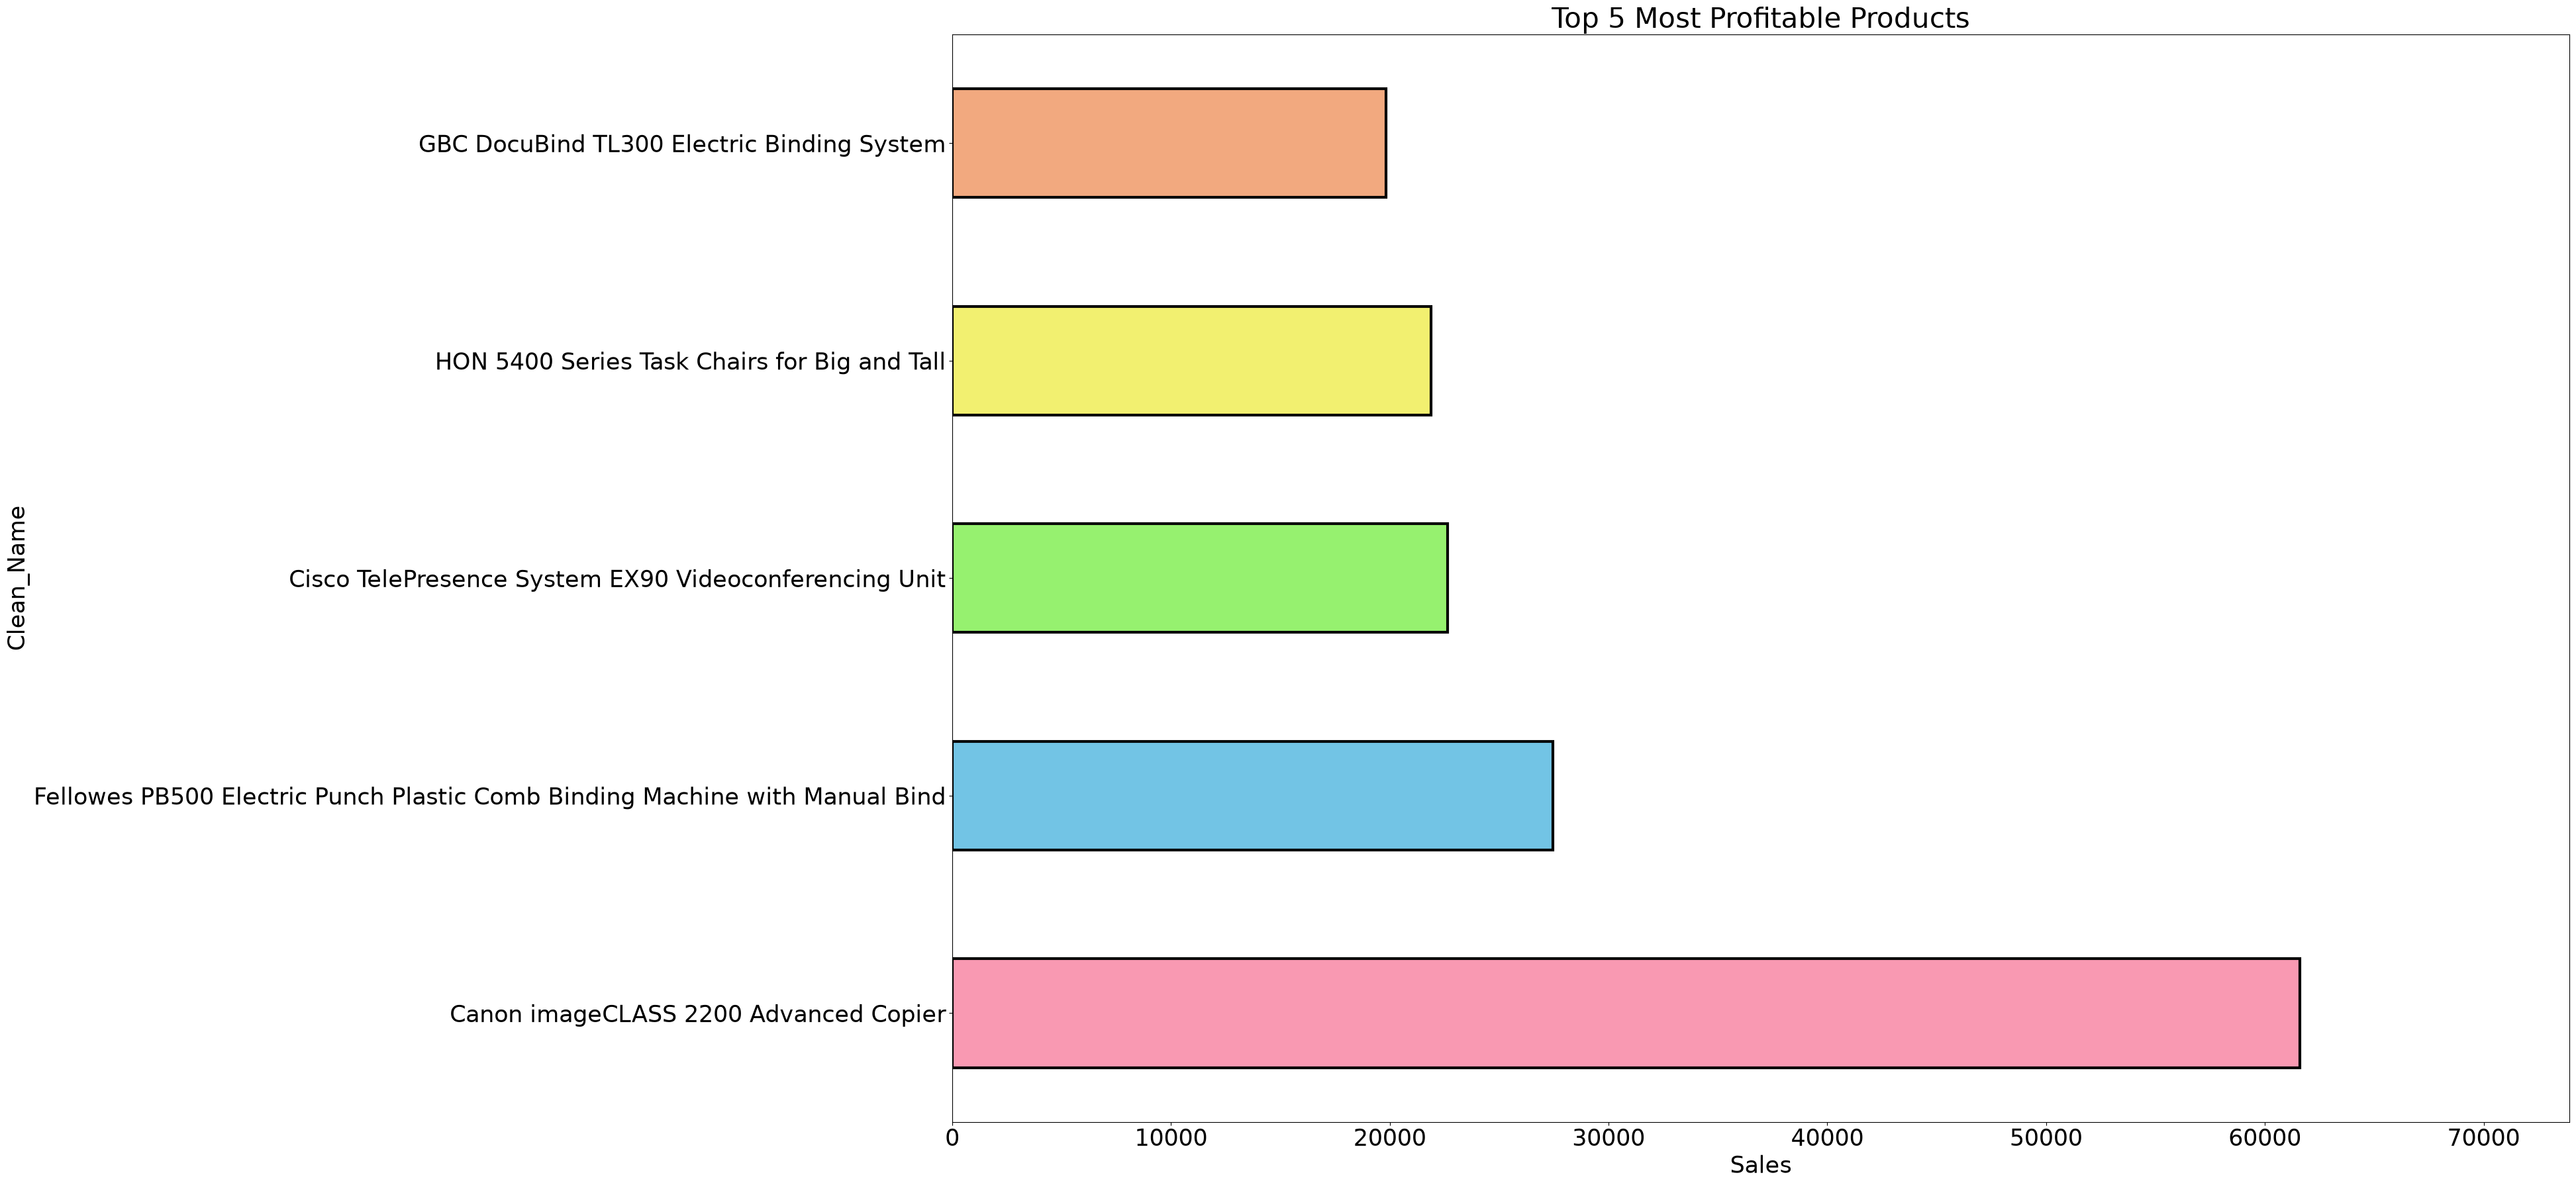

In [4]:
# 1. What percentage of those unique orders appear in returns?
ureturns = returns['Order ID'].nunique()
uorders = orders['Order ID'].nunique()
print("the percent is: ",(ureturns/uorders) * 100)
# series = orders['Country/Region'].value_counts()
# series.plot(kind = 'bar',title = 'Orders by Country/Region', xlabel = 'Country/Region', ylabel = 'Number of Orders',color = 'pink')
# plt.xticks(rotation=360)
# plt.show()

# most profitable product category
orders['Product ID'].nunique()

# top 5 most profitable products
profits = orders.groupby(['Product Name'])['Sales'].sum().sort_values(ascending=False).head(5)
fig, ax = plt.subplots(figsize=(39, 18))
orders['Clean_Name'] = orders['Product Name'].apply(
    lambda x: x[:30] + '...' if len(x) > 30 else x
)
profits.plot(kind='barh', ax=ax,
             color=["#F999B2","#72C4E5","#96F16F","#F2F070","#F2A97F"],linewidth=3, edgecolor='black')
ax.set_title('Top 5 Most Profitable Products', fontsize=30)
ax.set_yticklabels(profits.index, rotation_mode='anchor',fontsize = 25)
ax.set_xlabel('Sales', fontsize=25)
ax.set_ylabel('Clean_Name', fontsize=25)
ax.tick_params(axis='x', labelsize=25)
ax.set_xlim(right=max(profits.values) * 1.2)
plt.tight_layout()
plt.show()   


2) Loss Concentration Analysis

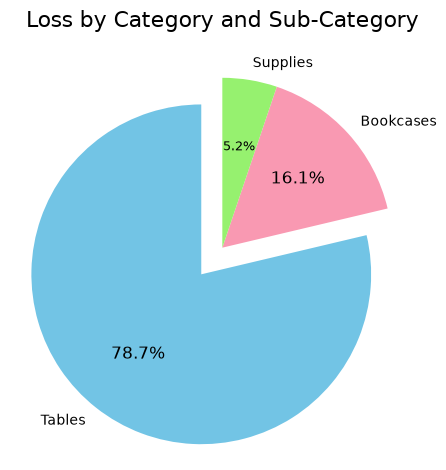

In [5]:
#Which product categories,sub-categories, or specific items are actually losing money?
worstcat = orders.groupby(['Category','Sub-Category'])['Profit'].sum().sort_values(ascending=True)
noprofit = worstcat[worstcat<0].sort_values(ascending = True)
noprofit.index
loss_labels = noprofit.index
submagnitudes = noprofit.abs() #what does abs() return here? It returns the absolute values of the negative profits, effectively converting them to positive numbers for visualization purposes. This allows us to represent the magnitude of losses without considering the sign, making it easier to compare the losses across different categories and sub-categories in the pie chart.
subcatnames = [item[1] for item in loss_labels]
res = plt.pie(submagnitudes, labels=subcatnames,autopct='%1.1f%%',startangle=90,colors = ["#72c4e5","#F999B2","#96F16F","#F2F070","#F2A97F"],explode = [0.2,0,0])
plt.title('Loss by Category and Sub-Category', fontsize=16)
for autotext in res[2]:
  if '5.2%' in autotext.get_text():
    autotext.set_fontsize(9)  # Make the tiny one smaller
  else:
    autotext.set_fontsize(12)
plt.tight_layout()
plt.show()
# noprofit.plot(kind = 'pie',autopct='%1.1f%%',title = 'Loss by Category and Sub-Category',ylabel = '',figsize=(10,10))

3.Discount Impact

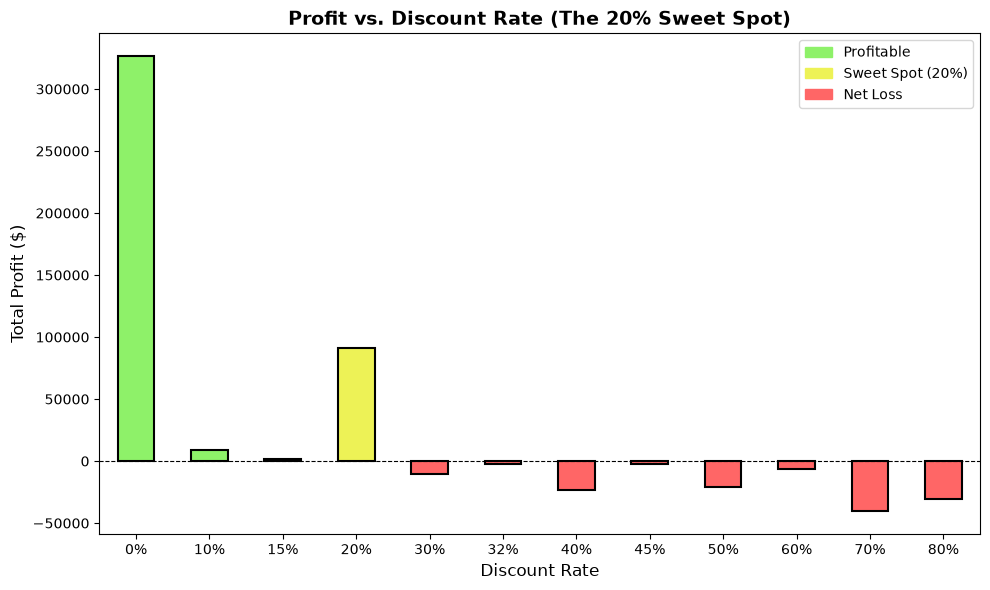

In [6]:
import matplotlib.patches as mpatches
profit_patch = mpatches.Patch(color="#8EF169", label='Profitable')
sweet_patch = mpatches.Patch(color="#edf256", label='Sweet Spot (20%)')
loss_patch = mpatches.Patch(color="#ff6666", label='Net Loss')
discounted = orders.groupby(['Discount'])['Profit'].sum().sort_index(ascending=True)
colors = []
for disc, p in discounted.items(): #(index, value) in discounted.items():
  if disc == 0.2:
    colors.append("#edf256")
  elif p > 0:
    colors.append('#8EF169') 
  else:
    colors.append('#ff6666') 
plt.figure(figsize=(10, 6))
bars = discounted.plot(kind='bar', color=colors,label=['green is profit, red is loss, yellow is the sweet spot'], edgecolor='black', linewidth=1.5)
plt.title(
    'Profit vs. Discount Rate (The 20% Sweet Spot)',
    fontsize=14,
    fontweight='bold',
)
plt.xlabel('Discount Rate', fontsize=12)
plt.ylabel('Total Profit ($)', fontsize=12)
plt.axhline(0, color='black', linewidth=0.8, linestyle='--') # what is 0 in the beginning of the line? It represents the y-coordinate where the horizontal line will be drawn, which is at y=0, indicating the break-even point between profit and loss.
plt.xticks(
    ticks=range(len(discounted.index)),
    labels=['0%', '10%', '15%', '20%', '30%', '32%', '40%', '45%', '50%', '60%', '70%', '80%'],
    rotation=0,
)
plt.legend(handles=[profit_patch, sweet_patch, loss_patch], loc='upper right')
plt.tight_layout() # what does tight_layout() do? It automatically adjusts the subplot parameters to give specified padding and prevent overlapping of plot elements, ensuring that labels, titles, and ticks are clearly visible and not cut off.
plt.show()

4. Geographical / Regional Performance

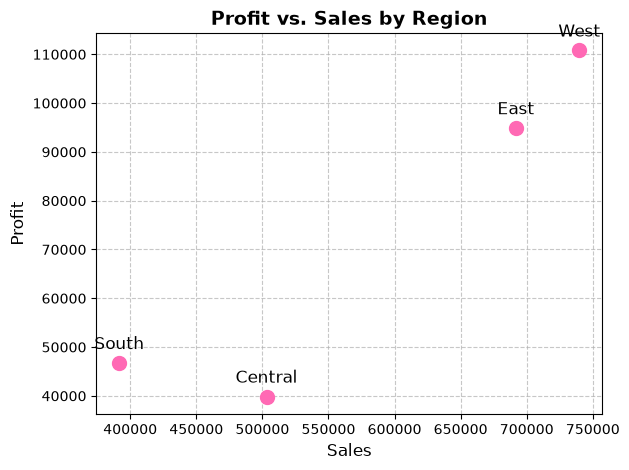

In [7]:
regions = orders.groupby(['Region']).agg({'Profit': 'sum','Sales':'sum'}).sort_values('Profit', ascending=True).reset_index() # reset.index() is used to reset the index of the DataFrame after sorting, so that the 'Region' column becomes a regular column again instead of being part of the index. This allows for easier access and manipulation of the data in subsequent operations.
plt.scatter(regions['Sales'], regions['Profit'], color='hotpink', s=100,zorder=2) # what are s and zorder? 's' specifies the size of the scatter plot markers, and 'zorder' determines the drawing order of the plot elements, with higher values being drawn on top of lower values.
for i,row in regions.iterrows():
    plt.annotate(
        row['Region'],(row['Sales'], row['Profit']),
        textcoords="offset points", xytext=(0,10), ha='center', fontsize=12,color='black')
plt.title('Profit vs. Sales by Region', fontsize=14, fontweight='bold')
plt.xlabel('Sales', fontsize=12)
plt.ylabel('Profit', fontsize=12)
plt.grid(True,linestyle='--',alpha=0.7)
plt.tight_layout()
plt.show()


5. Timetrends and Seasonality

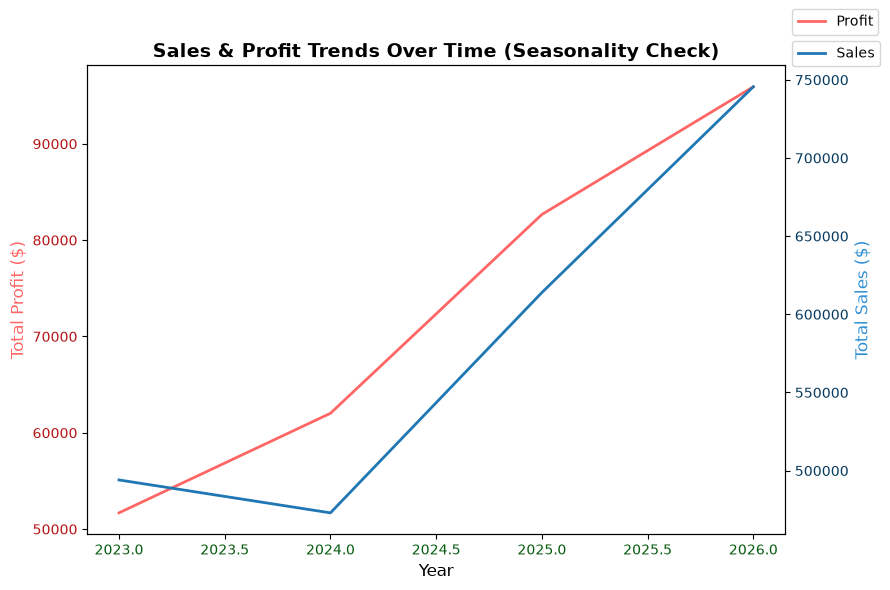

In [41]:
import matplotlib.pyplot as plt
orders['Order Date'] = pd.to_datetime(orders['Order Date'])
orders['Year'] = orders['Order Date'].dt.year
shower = orders.groupby(['Year']).agg({'Profit': 'sum', 'Sales': 'sum'}).sort_values('Year', ascending=True).reset_index()
fig, ax1 = plt.subplots(figsize=(9, 6))
ax1.plot(
    shower['Year'],
    shower['Profit'],
    color='#ff6666',
    linewidth=2,
    label='Profit',
)
ax1.set_ylabel('Total Profit ($)', color='#ff6666', fontsize=12)
ax1.tick_params(axis='y', labelcolor="#b61616")
ax1.set_xlabel('Year', fontsize=12)
plt.legend(loc='upper left', bbox_to_anchor=(1, 1.135))

ax2 = ax1.twinx()
ax2.plot(
    shower['Year'],
    shower['Sales'],
    color='#1f77b4',
    linewidth=2,
    label='Sales',
)
ax2.set_ylabel('Total Sales ($)', color="#2e8ed2", fontsize=12)
ax2.tick_params(axis='y', labelcolor="#073B60")
ax1.tick_params(axis='x', labelcolor = "#055c0f")
plt.title('Sales & Profit Trends Over Time (Seasonality Check)', fontsize=14, fontweight='bold')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1.067))
plt.tight_layout()